# QC results 

Summarizes QC rating across raters for a given dataset. Estimates inter-rate-reliability and other metrics based on available subject overlaps. 

Gathers every rater's QC output listed in `RATER_CONFIG` and builds dataset-level reports:

* **Which file is used.** Files live in each rater's `out_dir` (default `<rater_dir>/qc-output`) and are grouped per
  QC task by name: `<rater_id>_<pipeline>_<task>_qc_status.tsv` and `checkpoints/<rater_id>_<pipeline>_<task>_checkpoint_<stamp>.tsv`.
  For each rater and task, the `qc_status.tsv` is used when it exists; otherwise the newest checkpoint (by the stamp
  in its filename). With `PREFER_TRANSFORMED_CHECKPOINTS`, a checkpoint's `*_transformed.tsv` copy (current facet
  names) replaces the original of the same stamp.
* **Sanity check.** `qc_status.tsv` is rewritten on every save, so it should hold everything the newest checkpoint
  holds; `in_latest_ckpt_not_in_status` counts the participants for which it doesn't.
* **Comparisons.** Rated participants are checked against each rater's own `participant_list` and against the
  dataset-level `PARTICIPANT_LIST`. Comparison is on `participant_id` because the lists don't carry sessions.
* Repeated rows for the same rater, participant, session and facet keep the latest `timestamp`.

In [1]:
# --- Local paths --------------------------------------------------------------
# Machine-specific paths live in notebooks/local_config.json (gitignored).
# Create it by copying notebooks/local_config.example.json and editing the paths.
import json
from pathlib import Path

LOCAL_CONFIG = next(
    (p for p in (Path("local_config.json"), Path("notebooks") / "local_config.json") if p.is_file()), None
)
if LOCAL_CONFIG is None:
    raise FileNotFoundError(
        "notebooks/local_config.json not found: copy notebooks/local_config.example.json and set your paths"
    )
_local = json.loads(LOCAL_CONFIG.read_text())
print(f"Local config: {LOCAL_CONFIG.resolve()}")

RATER_CONFIG = _local["rater_config"]            # raters whose outputs are collated
PARTICIPANT_LIST = _local["participant_list"]    # dataset-level participant pool
OUTPUT_DIR = _local.get("output_dir")            # write report TSVs here (None = don't save)

# --- Settings ---------------------------------------------------------------
# When the chosen checkpoint has a *_transformed.tsv copy (current facet names), use it
PREFER_TRANSFORMED_CHECKPOINTS = True


In [2]:
import sys
from pathlib import Path

import pandas as pd

# Reuse the app's config parser so path resolution matches QC-Studio exactly.
REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "ui" / "utils" / "user_config.py").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "ui"))
from utils.user_config import load_users_config

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

Helpers: rating-file discovery and selection.

In [3]:
import re
from datetime import datetime

import matplotlib.pyplot as plt

import numpy as np

ID_COLS = ["participant_id", "session_id", "task_id", "run_id"]
RATING_KEY = ["rater_id", "pipeline", "qc_task"] + ID_COLS
QC_ORDER = ["All-Pass", "Mixed", "All-Uncertain", "All-Fail", "All-Missing"]
VALUE_ORDER = ["PASS", "UNCERTAIN", "FAIL", "MISSING"]
# Status colors (good / warning / serious / critical) + neutral gray for missing.
QC_COLORS = {"All-Pass": "#0ca30c", "Mixed": "#fab219", "All-Uncertain": "#ec835a",
             "All-Fail": "#d03b3b", "All-Missing": "#898781"}
VALUE_COLORS = {"PASS": "#0ca30c", "UNCERTAIN": "#ec835a", "FAIL": "#d03b3b", "MISSING": "#898781"}
# Same stamp format the app writes/parses (landing_page._CHECKPOINT_STAMP_RE).
_CKPT_RE = re.compile(r"^(?P<stem>.+)_checkpoint_(?P<stamp>\d{8}T\d{6})Z?(?P<suffix>_[^/]*)?\.tsv$")


def read_ids(path):
    """Unique, non-blank participant_id values from a TSV (empty list if the file is missing)."""
    if not Path(path).is_file():
        return []
    df = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    if "participant_id" not in df.columns:
        raise ValueError(f"{path}: no participant_id column")
    ids = df["participant_id"].str.strip()
    return ids[ids != ""].unique().tolist()


def read_ratings(path):
    df = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    return df.apply(lambda s: s.str.strip())


def find_rating_files(rater):
    """All status/checkpoint TSVs in a rater's out_dir as rows: rater_id, task_key, kind, stamp, transformed, path.

    task_key is the "<pipeline>_<task>" slug between the rater_id prefix and the _qc_status/_checkpoint suffix.
    """
    rid, out = rater["rater_id"], Path(rater["out_dir"])
    rows = []
    for p in sorted(out.glob("*_qc_status.tsv")):
        stem = p.name[: -len("_qc_status.tsv")]
        rows.append((stem, "status", pd.NaT, False, p))
    for p in sorted((out / "checkpoints").glob("*.tsv")):
        m = _CKPT_RE.match(p.name)
        if not m:
            print(f"WARNING {rid}: unrecognized checkpoint name {p.name}; skipped")
            continue
        stamp = datetime.strptime(m["stamp"], "%Y%m%dT%H%M%S")
        rows.append((m["stem"], "checkpoint", stamp, m["suffix"] == "_transformed", p))
    files = pd.DataFrame(rows, columns=["stem", "kind", "stamp", "transformed", "path"])
    prefix = f"{rid}_"
    bad = ~files["stem"].str.startswith(prefix)
    if bad.any():
        print(f"WARNING {rid}: files not prefixed with {prefix!r} skipped: {files.loc[bad, 'path'].map(lambda p: p.name).tolist()}")
    files = files[~bad]
    files.insert(0, "task_key", files.pop("stem").str[len(prefix):])
    files.insert(0, "rater_id", rid)
    return files


def select_rating_file(files, prefer_transformed=True):
    """The current rating file for one (rater, task_key): the qc_status.tsv if present, else the newest checkpoint.

    For the chosen checkpoint stamp, its *_transformed.tsv variant (current facet schema) is used when
    prefer_transformed is True and it exists.
    """
    status = files[files["kind"] == "status"]
    ckpts = files[files["kind"] == "checkpoint"]
    latest_ckpt = None
    if not ckpts.empty:
        newest = ckpts[ckpts["stamp"] == ckpts["stamp"].max()]
        pick = newest[newest["transformed"] == prefer_transformed]
        latest_ckpt = (pick if not pick.empty else newest).iloc[0]
    chosen = status.iloc[0] if not status.empty else latest_ckpt
    return chosen, latest_ckpt, len(ckpts.drop_duplicates("stamp"))

## 1. Find and load each rater's current rating file

In [4]:
cfg_r = load_users_config(RATER_CONFIG)
pool_ids = set(read_ids(PARTICIPANT_LIST))
print(f"Dataset participant list: {PARTICIPANT_LIST}  ({len(pool_ids)} participants)")

assigned = {u["rater_id"]: set(read_ids(u["participant_list"])) for u in cfg_r.users.values()}

sources, frames, no_files = [], [], []
for u in sorted(cfg_r.users.values(), key=lambda u: u["rater_id"]):
    files = find_rating_files(u)
    if files.empty:
        no_files.append(u["rater_id"])
        continue
    for task_key, g in files.groupby("task_key"):
        chosen, latest_ckpt, n_ckpts = select_rating_file(g, PREFER_TRANSFORMED_CHECKPOINTS)
        df = read_ratings(chosen["path"])
        ids = set(df["participant_id"])
        # Sanity check: a status file normally contains everything the newest checkpoint has.
        ckpt_only = 0
        if chosen["kind"] == "status" and latest_ckpt is not None:
            ckpt_only = len(set(read_ratings(latest_ckpt["path"])["participant_id"]) - ids)
        wrong_rater = sorted(set(df["rater_id"]) - {u["rater_id"]}) if "rater_id" in df else []
        if wrong_rater:
            print(f"WARNING {chosen['path'].name}: rater_id column has {wrong_rater}; overwritten with {u['rater_id']!r}")
        df["rater_id"] = u["rater_id"]
        df["task_key"] = task_key
        df["source_kind"] = chosen["kind"]
        df["source_file"] = chosen["path"].name
        frames.append(df)
        sources.append({
            "rater_id": u["rater_id"], "task_key": task_key, "source_kind": chosen["kind"],
            "source_file": chosen["path"].name,
            "checkpoint_stamp": "" if pd.isna(chosen["stamp"]) else chosen["stamp"].strftime("%Y-%m-%d %H:%M"),
            "last_rating": df["timestamp"].max(),
            "n_checkpoints": n_ckpts, "n_participants": len(ids),
            "in_latest_ckpt_not_in_status": ckpt_only,
        })

sources_df = pd.DataFrame(sources)
ratings = pd.concat(frames, ignore_index=True)
# Keep the latest rating per rater/participant/facet in case a file holds repeats.
n_before = len(ratings)
ratings = (ratings.sort_values("timestamp")
           .drop_duplicates(RATING_KEY + ["facet"], keep="last")
           .reset_index(drop=True))

print(f"Raters with rating files: {sources_df['rater_id'].nunique()} / {len(cfg_r.users)}")
if no_files:
    print(f"No status/checkpoint files yet: {', '.join(no_files)}")
print(f"Facet-level ratings: {len(ratings)} rows ({n_before - len(ratings)} duplicate rows dropped)")
display(sources_df)
flag = sources_df[sources_df["in_latest_ckpt_not_in_status"] > 0]
if not flag.empty:
    print("WARNING: newest checkpoint has participants missing from the status file:")
    display(flag)

Dataset participant list: /home/nikhil/projects/Parkinsons/ppmi/qc/qc_participants.tsv  (3165 participants)
Raters with rating files: 11 / 17
No status/checkpoint files yet: eloisev, jishangj, mwang, nikhil, odysseus, vanheese
Facet-level ratings: 5056 rows (0 duplicate rows dropped)


,rater_id,task_key,source_kind,source_file,checkpoint_stamp,last_rating,n_checkpoints,n_participants,in_latest_ckpt_not_in_status
0,achillev,fsqc_fs_preproc_workflow,checkpoint,achillev_fsqc_fs_preproc_workflow_checkpoint_2...,2026-11-06 20:55,2026-11-06 20:55:18,2,25,0
1,achillev,fsqc_fs_surface_workflow,checkpoint,achillev_fsqc_fs_surface_workflow_checkpoint_2...,2026-11-06 20:48,2026-11-06 20:48:12,5,24,0
2,achillev,fsqc_fs_volume_workflow,checkpoint,achillev_fsqc_fs_volume_workflow_checkpoint_20...,2026-11-06 20:36,2026-11-06 20:36:37,4,25,0
3,aishaa,fsqc_fs_preproc_workflow,checkpoint,aishaa_fsqc_fs_preproc_workflow_checkpoint_202...,2026-10-07 14:51,2026-10-07 14:51:55,1,9,0
4,aishaa,fsqc_fs_surface_workflow,checkpoint,aishaa_fsqc_fs_surface_workflow_checkpoint_202...,2026-10-07 15:24,2026-10-07 15:24:50,1,7,0
5,aishaa,fsqc_fs_volume_workflow,checkpoint,aishaa_fsqc_fs_volume_workflow_checkpoint_2026...,2026-10-07 15:30,2026-10-07 15:30:17,1,3,0
6,casd,fsqc_fs_preproc_workflow,checkpoint,casd_fsqc_fs_preproc_workflow_checkpoint_20261...,2026-10-08 14:08,2026-10-08 14:08:51,6,182,0
7,charlottel,fsqc_fs_preproc_workflow,checkpoint,charlottel_fsqc_fs_preproc_workflow_checkpoint...,2026-11-06 16:25,2026-11-06 16:25:58,3,90,0
8,charlottel,fsqc_fs_surface_workflow,checkpoint,charlottel_fsqc_fs_surface_workflow_checkpoint...,2026-11-06 21:06,2026-11-06 21:06:44,21,77,0
9,daniquek,fsqc_fs_preproc_workflow,checkpoint,daniquek_fsqc_fs_preproc_workflow_checkpoint_2...,2026-10-07 15:34,2026-10-07 15:34:54,7,60,0


## 2. Participant-level ratings

One row per rater × task × participant/session, with its `final_qc` and the number of failing, uncertain and missing facets.

In [5]:
def _count(value):
    return lambda s: int((s == value).sum())

qc = (ratings.groupby(RATING_KEY + ["task_key", "source_kind"], as_index=False)
      .agg(final_qc=("final_qc", "last"), timestamp=("timestamp", "max"), n_facets=("facet", "size"),
           n_fail=("rating_value", _count("FAIL")), n_uncertain=("rating_value", _count("UNCERTAIN")),
           n_missing=("rating_value", _count("MISSING"))))
tasks = sorted(qc["qc_task"].unique())
print(f"Participant-level ratings: {len(qc)} (rater x task x participant/session)")
display(pd.crosstab([qc["pipeline"], qc["qc_task"]], qc["final_qc"]).reindex(columns=QC_ORDER, fill_value=0))

Participant-level ratings: 688 (rater x task x participant/session)


final_qc                      All-Pass  Mixed  All-Uncertain  All-Fail  All-Missing
pipeline qc_task                                                                   
fsqc     FS_preproc_workflow       302    104              4         0           35
         FS_surface_workflow       125     71              2         5            0
         FS_volume_workflow         27     11              2         0            0

## 3. Rater progress

Per rater and task: participants rated out of the rater's own list, plus anyone rated outside that list or outside the dataset list.

,rater_id,pipeline,qc_task,assigned,rated,rated_assigned,pct_complete,rated_not_assigned,rated_not_in_pool,All-Pass,Mixed,All-Uncertain,All-Fail,All-Missing
0,achillev,fsqc,FS_preproc_workflow,243,25,25,10.3,0,0,17,0,0,0,8
1,achillev,fsqc,FS_surface_workflow,243,24,24,9.9,0,0,12,12,0,0,0
2,achillev,fsqc,FS_volume_workflow,243,25,25,10.3,0,0,20,3,2,0,0
3,aishaa,fsqc,FS_preproc_workflow,243,9,9,3.7,0,0,8,1,0,0,0
4,aishaa,fsqc,FS_surface_workflow,243,7,7,2.9,0,0,7,0,0,0,0
5,aishaa,fsqc,FS_volume_workflow,243,3,3,1.2,0,0,3,0,0,0,0
6,casd,fsqc,FS_preproc_workflow,243,182,182,74.9,0,0,122,60,0,0,0
7,charlottel,fsqc,FS_preproc_workflow,243,90,90,37.0,0,0,59,0,4,0,27
8,charlottel,fsqc,FS_surface_workflow,243,77,77,31.7,0,0,32,42,2,1,0
9,daniquek,fsqc,FS_preproc_workflow,243,60,60,24.7,0,0,41,19,0,0,0


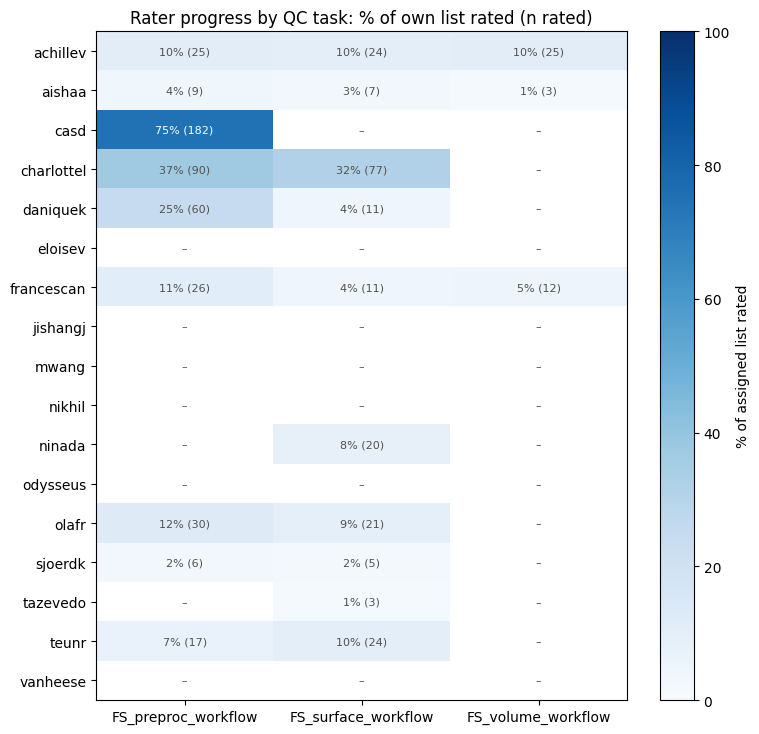

In [6]:
rows = []
for (rid, pipe, task), g in qc.groupby(["rater_id", "pipeline", "qc_task"]):
    rated, mine = set(g["participant_id"]), assigned.get(rid, set())
    rows.append({
        "rater_id": rid, "pipeline": pipe, "qc_task": task,
        "assigned": len(mine), "rated": len(rated), "rated_assigned": len(rated & mine),
        "pct_complete": round(100 * len(rated & mine) / len(mine), 1) if mine else np.nan,
        "rated_not_assigned": len(rated - mine), "rated_not_in_pool": len(rated - pool_ids),
        **{q: int((g["final_qc"] == q).sum()) for q in QC_ORDER},
    })
progress = pd.DataFrame(rows)
display(progress)
odd = progress[(progress["rated_not_assigned"] > 0) | (progress["rated_not_in_pool"] > 0)]
if not odd.empty:
    print("Raters who rated participants outside their own list or outside the dataset list:")
    display(qc.assign(
        assigned=[p in assigned.get(r, set()) for r, p in zip(qc["rater_id"], qc["participant_id"])],
        in_pool=qc["participant_id"].isin(pool_ids),
    ).query("not assigned or not in_pool")[["rater_id", "qc_task", "participant_id", "session_id", "assigned", "in_pool"]])

# Heatmap: % of each rater's list completed per task (blank = task not started)
pct = progress.pivot(index="rater_id", columns="qc_task", values="pct_complete")
pct = pct.reindex(index=sorted(cfg_r.users[e]["rater_id"] for e in cfg_r.users), columns=tasks)
cnt = progress.pivot(index="rater_id", columns="qc_task", values="rated_assigned").reindex_like(pct)
fig, ax = plt.subplots(figsize=(1.6 * len(tasks) + 3, 0.35 * len(pct) + 1.5))
im = ax.imshow(pct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(tasks)), tasks)
ax.set_yticks(range(len(pct)), pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        v = pct.iat[i, j]
        ax.text(j, i, "–" if pd.isna(v) else f"{v:.0f}% ({int(cnt.iat[i, j])})", ha="center", va="center",
                fontsize=8, color="white" if (not pd.isna(v) and v > 60) else "#52514e")
fig.colorbar(im, ax=ax, label="% of assigned list rated")
ax.set_title("Rater progress by QC task: % of own list rated (n rated)")
plt.tight_layout()
plt.show()

## 4. Dataset coverage against `PARTICIPANT_LIST`

How many participants in the dataset list have been rated per task, and by how many raters.

,pipeline,qc_task,pool,assigned_to_any_rater,rated_1+,rated_2+,rated_3+,not_rated,pct_rated,rated_not_in_pool,n_sessions
0,fsqc,FS_preproc_workflow,3165,3165,445,0,0,2720,14.1,0,1
1,fsqc,FS_surface_workflow,3165,3165,203,0,0,2962,6.4,0,1
2,fsqc,FS_volume_workflow,3165,3165,40,0,0,3125,1.3,0,1


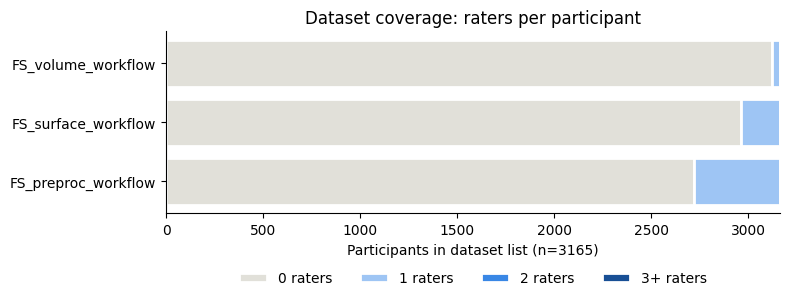

In [7]:
n_assigned = pd.Series([p for ids in assigned.values() for p in ids]).value_counts()
rows = []
for (pipe, task), g in qc.groupby(["pipeline", "qc_task"]):
    n_r = g.drop_duplicates(["participant_id", "rater_id"]).groupby("participant_id")["rater_id"].nunique()
    in_pool = n_r.reindex(sorted(pool_ids), fill_value=0)
    rows.append({
        "pipeline": pipe, "qc_task": task, "pool": len(pool_ids),
        "assigned_to_any_rater": int(n_assigned.index.isin(list(pool_ids)).sum()),
        "rated_1+": int((in_pool >= 1).sum()), "rated_2+": int((in_pool >= 2).sum()),
        "rated_3+": int((in_pool >= 3).sum()), "not_rated": int((in_pool == 0).sum()),
        "pct_rated": round(100 * (in_pool >= 1).mean(), 1),
        "rated_not_in_pool": len(set(n_r.index) - pool_ids),
        "n_sessions": g["session_id"].nunique(),
    })
coverage_qc = pd.DataFrame(rows)
display(coverage_qc)
assigned_not_in_pool = set(n_assigned.index) - pool_ids
if assigned_not_in_pool:
    print(f"WARNING: {len(assigned_not_in_pool)} participants in rater lists are not in the dataset list, "
          f"e.g. {sorted(assigned_not_in_pool)[:5]}")

# Stacked bars: how many raters each pool participant has per task
bins = ["0", "1", "2", "3+"]
dist = pd.DataFrame({
    t: (qc[qc["qc_task"] == t].drop_duplicates(["participant_id", "rater_id"])
        .groupby("participant_id")["rater_id"].nunique()
        .reindex(sorted(pool_ids), fill_value=0).clip(upper=3).astype(str).replace("3", "3+")
        .value_counts().reindex(bins, fill_value=0))
    for t in tasks
}).T
fig, ax = plt.subplots(figsize=(8, 0.6 * len(tasks) + 1.5))
left = np.zeros(len(dist))
for b, color in zip(bins, ["#e1e0d9", "#9ec5f4", "#3987e5", "#184f95"]):
    ax.barh(dist.index, dist[b], left=left, color=color, edgecolor="white", linewidth=2, label=f"{b} raters")
    left += dist[b].values
ax.set_xlabel(f"Participants in dataset list (n={len(pool_ids)})")
ax.set_title("Dataset coverage: raters per participant")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Rating distributions

`final_qc` mix per rater (to spot lenient or strict raters), and the facet-level rating mix per task (which facets fail most).

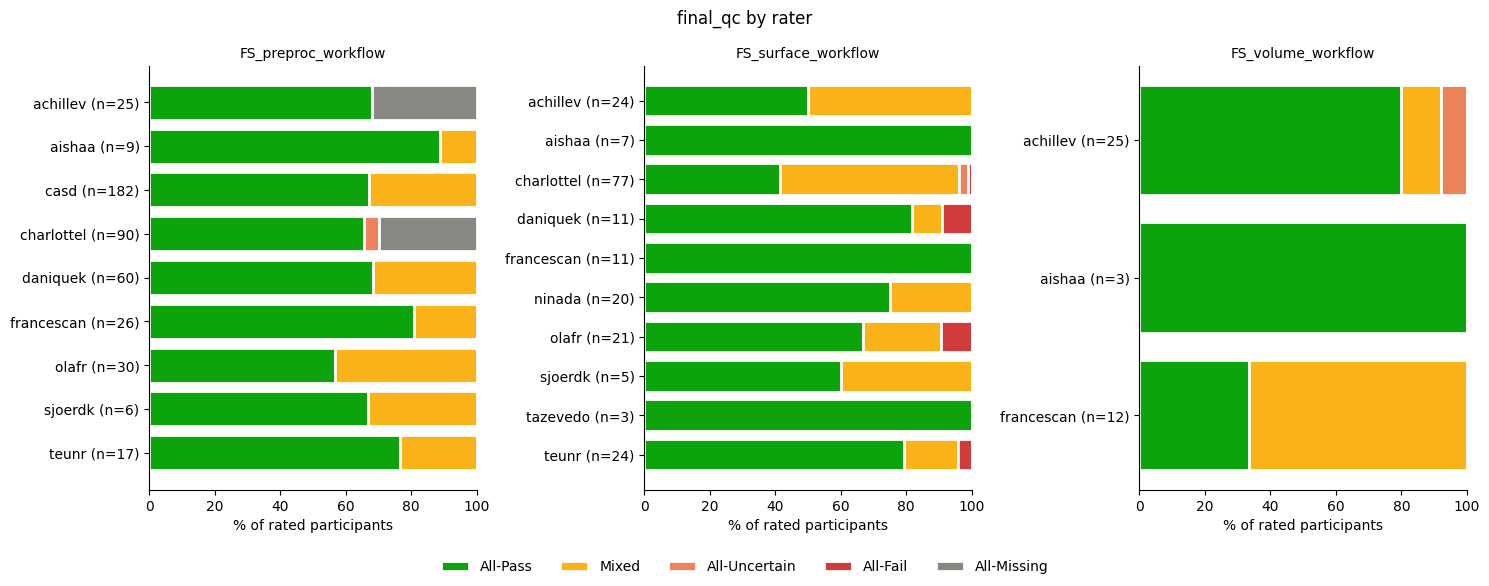

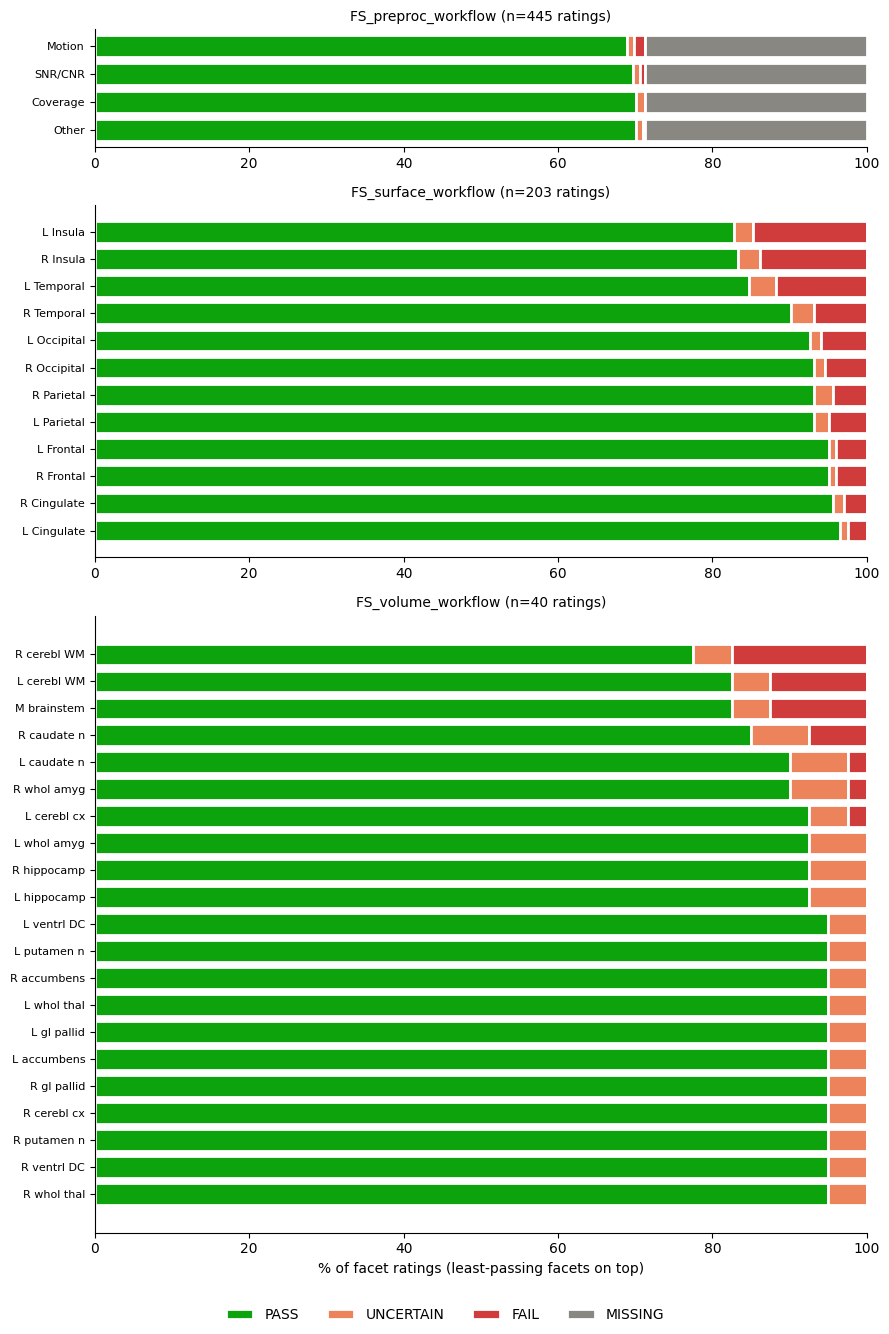

In [8]:
def stacked_share(ax, table, order, colors, title):
    share = table.reindex(columns=order, fill_value=0)
    share = 100 * share.div(share.sum(axis=1), axis=0)
    left = np.zeros(len(share))
    for c in order:
        ax.barh(share.index, share[c], left=left, color=colors[c], edgecolor="white", linewidth=2, label=c)
        left += share[c].values
    ax.set_xlim(0, 100)
    ax.set_title(title, fontsize=10)
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)

# final_qc mix per rater, one panel per task (spots lenient / strict raters)
fig, axes = plt.subplots(1, len(tasks), figsize=(5 * len(tasks), 0.35 * qc["rater_id"].nunique() + 2), squeeze=False)
for ax, t in zip(axes[0], tasks):
    g = qc[qc["qc_task"] == t]
    tab = pd.crosstab(g["rater_id"], g["final_qc"])
    stacked_share(ax, tab, QC_ORDER, QC_COLORS, f"{t}")
    ax.set_yticks(range(len(tab)), [f"{r} (n={n})" for r, n in tab.sum(axis=1).items()])
    ax.set_xlabel("% of rated participants")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=len(QC_ORDER), loc="lower center", frameon=False)
fig.suptitle("final_qc by rater")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

# Facet-level rating mix per task (which facets fail most)
fig, axes = plt.subplots(len(tasks), 1, figsize=(9, sum(0.28 * ratings.loc[ratings["qc_task"] == t, "facet"].nunique() + 1 for t in tasks)),
                         squeeze=False, gridspec_kw={"height_ratios": [ratings.loc[ratings["qc_task"] == t, "facet"].nunique() for t in tasks]})
for ax, t in zip(axes[:, 0], tasks):
    g = ratings[ratings["qc_task"] == t]
    tab = pd.crosstab(g["facet"], g["rating_value"])
    tab = tab.loc[tab.reindex(columns=["PASS"], fill_value=0)["PASS"].div(tab.sum(axis=1)).sort_values().index]
    stacked_share(ax, tab, VALUE_ORDER, VALUE_COLORS, f"{t} (n={g[RATING_KEY].drop_duplicates().shape[0]} ratings)")
    ax.tick_params(axis="y", labelsize=8)
axes[-1, 0].set_xlabel("% of facet ratings (least-passing facets on top)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=len(VALUE_ORDER), loc="lower center", frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 6. Participants rated by more than one rater

`majority_qc` is the `final_qc` given by more than half of the raters, else `No majority`.

In [9]:
def consensus(g):
    vc = g["final_qc"].value_counts()
    n = int(vc.sum())
    return pd.Series({
        "n_raters": n,
        "raters": ", ".join(sorted(g["rater_id"])),
        "ratings": ", ".join(f"{k}:{v}" for k, v in vc.items()),
        "unanimous": len(vc) == 1,
        "majority_qc": vc.index[0] if vc.iloc[0] > n / 2 else "No majority",
    })

cons = (qc.groupby(["pipeline", "qc_task"] + ID_COLS)
        .apply(consensus, include_groups=False).reset_index())
multi = cons[cons["n_raters"] > 1]
print(f"Participants rated by >1 rater: {len(multi)} (task x participant/session)")
display(multi.groupby("qc_task").agg(n=("unanimous", "size"), unanimous=("unanimous", "sum"))
        .assign(pct_unanimous=lambda d: (100 * d["unanimous"] / d["n"]).round(1)))
display(multi[~multi["unanimous"]].head(20))

Participants rated by >1 rater: 0 (task x participant/session)


,n,unanimous,pct_unanimous
qc_task,,,


,pipeline,qc_task,participant_id,session_id,task_id,run_id,n_raters,raters,ratings,unanimous,majority_qc


## 7. Save reports (when `OUTPUT_DIR` is set)

In [ ]:
if OUTPUT_DIR:
    out = Path(OUTPUT_DIR)
    out.mkdir(parents=True, exist_ok=True)
    for name, df in {
        "qc_ratings_facets": ratings, "qc_ratings_participants": qc, "qc_consensus": cons,
        "qc_rater_progress": progress, "qc_dataset_coverage": coverage_qc, "qc_source_files": sources_df,
    }.items():
        df.to_csv(out / f"{name}.tsv", sep="\t", index=False)
        print(f"wrote {out / f'{name}.tsv'} ({len(df)} rows)")
else:
    print("OUTPUT_DIR is None: reports not saved")